# A digital twin of current sharing in a superconducting circuit

Fusion magnets are wound from cables of many parallel superconducting
(REBCO) tapes. When one tape approaches its critical current, current moves
into the other tapes. A *digital twin* of the magnet must predict this while the
magnet runs, faster than a physics simulation can. The usual approach is to
run the simulator offline many times and train a fast *surrogate* model on
the results.

The key design decision is the *loss function*: the number that training
makes as small as possible. In class you build it in three levels:

| Level | What you do |
|---|---|
| **1** | Write a loss on the tape currents, and check the voltages it implies |
| **2** | Put Kirchhoff's voltage law into the loss |
| **3** | Tune the loss so that currents *and* voltages meet a target |

After class, three **optional homework** problems let you run the circuit
simulator yourself, measure how much data the surrogate needs, and try a
broken-sensor challenge.

Each level prints ✅ when you reach it. Run the cells in order with
**Shift+Enter**. If something goes wrong, restart the kernel and run the cells
again from the top.

In [ ]:
# Setup: unpacks the sc_twin package (simulator, model, training code, data).
import base64, io, sys, tempfile, zipfile
_folder = tempfile.mkdtemp()
zipfile.ZipFile(io.BytesIO(base64.b64decode('...'))).extractall(_folder)
sys.path.insert(0, _folder)
for _name in [m for m in sys.modules if m.split('.')[0] == 'sc_twin']:
    del sys.modules[_name]
import numpy as np
import matplotlib.pyplot as plt
from sc_twin import *
EPOCHS = 320
print('Ready.')

### The circuit

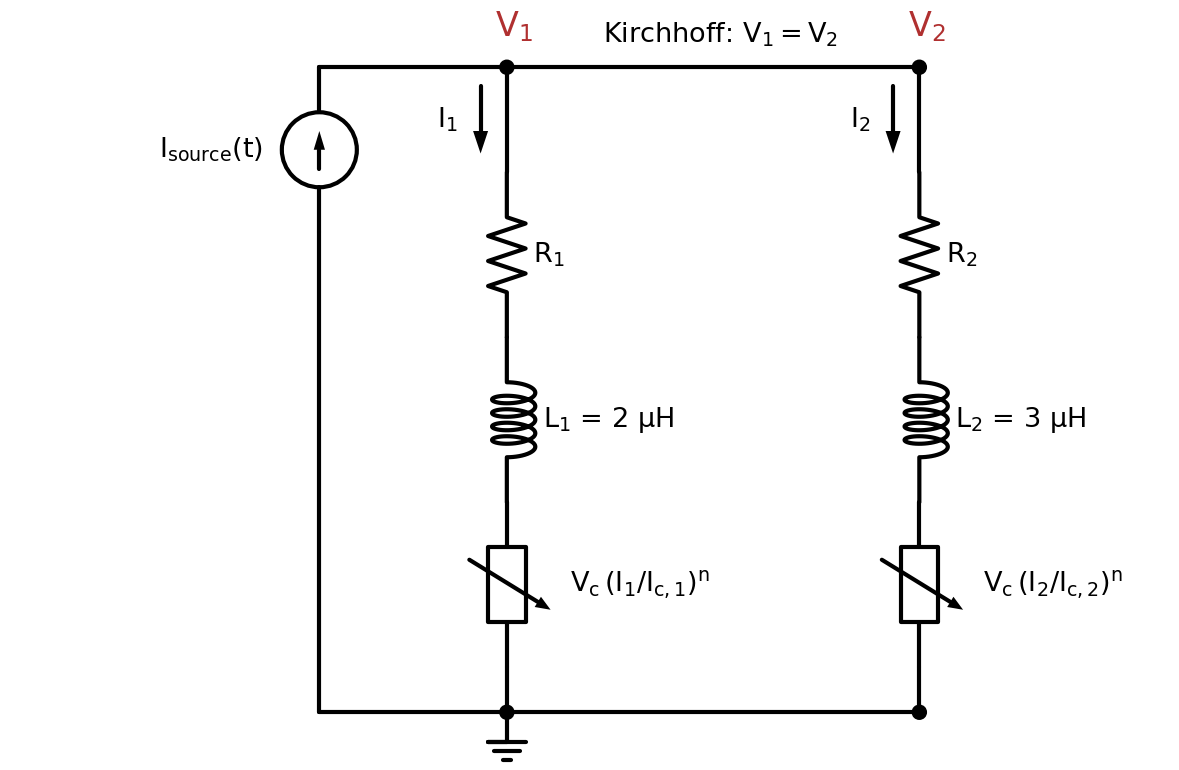

A current source feeds two parallel REBCO tapes, each 1 m long; each branch
of the circuit is one tape. Branch $k$ contains the termination resistance $R_k$,
where the tape is soldered to the terminals, the tape inductance
$L_k$, and the superconducting layer, whose voltage follows the power law

$$V_{\mathrm{sc},k}(I_k)=V_c\left(\frac{I_k}{I_{c,k}}\right)^{n},\qquad
V_c = E_c\,\ell = 100\,\mu\mathrm{V}\ (E_c = 100\,\mu\mathrm{V/m},\ \ell = 1\,\mathrm{m}),\qquad n = 10.$$

| Parameter | Value |
|---|---|
| Critical current $I_{c,1}$, $I_{c,2}$ | 120–180 A (different for every ramp) |
| Termination resistance $R_1$, $R_2$ | 20–250 nΩ (different for every ramp) |
| Inductance $L_1$, $L_2$ | 2 µH, 3 µH |
| Final source current | 85–100% of $I_{c,1} + I_{c,2}$, reached in 3.5–4.8 s |

The voltage is negligible at low current and rises steeply as the current
approaches the critical current $I_{c,k}$: at $1.2\,I_{c}$ it is already 6
times $V_c$. The source ramps up from zero and is then held constant. The
power law and the termination resistances follow the circuit model of Araujo Martínez
*et al.*, IEEE Trans. Appl. Supercond. **30**, 6600605 (2020); the inductances
are assumed. Commercial REBCO tapes have $n$ of 20–40 (the paper uses 30). We
use $n = 10$ because a steeper law makes the voltages much harder for a small
surrogate to get right; optional homework 1 lets you change it. This is still a simplified teaching model: there is no
temperature, no magnetic coupling or electrical contact between the tapes, and
no quench.

In [ ]:
plot_introduction()

**Question:** Early in the ramp, which tape carries more current, and why?
Late in the ramp, how does a lower critical current change the split?

✏️ **Your answer** *(double-click this cell to edit it, Shift+Enter to finish)*:

...

### The training data

The surrogate learns from 30 simulated ramps, not from one. Each ramp is a
different cable: both critical currents, both termination resistances, the final
source current and the ramp duration are drawn at random from the ranges in
the table above. Each ramp is recorded every 0.1 s for 6 s, so the training set
has 30 × 61 = 1830 points. Seven more ramps are used only for *validation*,
to measure how well the surrogate works on cables it has not seen, and one
*test* ramp, used for neither, is shown in the plots. Each point gives the model seven
inputs (source current, time, ramp rate, $I_{c,1}$, $I_{c,2}$, $R_1$, $R_2$)
and two outputs to predict: the tape currents $I_1$ and $I_2$.

In [ ]:
plot_training_data()

### Checking currents against the circuit laws

Both branches connect the same two nodes, so by **Kirchhoff's voltage law**
they must have the same voltage at every moment:

$$V_k = R_k I_k + L_k\frac{dI_k}{dt} + V_{\mathrm{sc},k}(I_k),\qquad V_1 = V_2.$$

The function `branch_voltages(currents, circuit)` computes $V_1$ and $V_2$
(in µV) from any set of tape currents; $dI/dt$ is the change between two
consecutive samples, 0.1 s apart. The cell below applies it to the simulated
currents, and then to currents that are wrong by only 1%.

In [ ]:
kirchhoff_check()

**Question:** Why can a 1% current error produce a much larger voltage error?
Look again at the voltage–current curves.

✏️ **Your answer** *(double-click this cell to edit it, Shift+Enter to finish)*:

...

### The surrogate

The surrogate is a small neural network. At each recorded time it receives
seven numbers (the source current, time, ramp rate, the two critical currents
and the two termination resistances) and predicts the two tape currents:

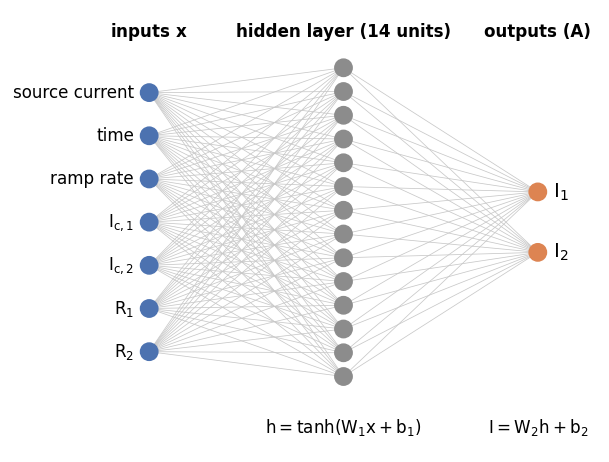

Each of the 14 hidden units takes a weighted sum of the inputs plus an offset
and passes it through $\tanh$; each output is a weighted sum of the hidden
units. Training adjusts the weights $W_1$, $W_2$ and offsets $b_1$, $b_2$
(142 numbers in all) so that your loss becomes as small as possible.

`train_and_report(loss, name)` trains the network with your loss, scores the
result on the validation ramps, plots the test ramp, and keeps a scoreboard of
your attempts. What the scores mean is explained after your first run. To read
the training code: `show_code(train_model)`.

## Level 1 — A loss on the currents

Write a loss that measures how far the predicted tape currents are from the
simulated ones. Replace `raise NotImplementedError(...)` with your equation.

| Variable | Shape | Meaning |
|---|---|---|
| `predicted` | `(number of points, 2)` | Predicted tape currents (A) |
| `measured` | `(number of points, 2)` | Simulated tape currents (A) |
| `total_current` | `(number of points,)` | Source current (A) |
| `circuit` | dictionary | Circuit data, used in Level 2 |

The loss must return a single number. Inside it, use `xp`. A few examples:

| Expression | Result |
|---|---|
| `predicted[:, 0]` | the predicted currents of tape 1, one per point |
| `predicted - measured` | the error of every point and tape, shape `(points, 2)` |
| `xp.mean(predicted)` | the mean of all predicted currents: one number |
| `xp.mean(predicted[:, 1])` | the mean predicted current of tape 2 |
| `xp.sum(predicted, axis=1)` | the sum of the two tape currents at each point |
| `xp.abs(x)`, `x**2`, `xp.sqrt(x)`, `xp.exp(x)` | element by element, as in NumPy |

<details><summary>What is xp?</summary>

`xp` works like NumPy and has the same function names (`xp.mean`, `xp.sum`,
`xp.abs`, `xp.sqrt`, `xp.exp`, `xp.log`), but it also records every operation
in your loss. The training code then goes back through that record to compute
how the loss changes with each predicted current: the gradient that training
needs (*automatic differentiation*). Libraries such as PyTorch and JAX do the
same thing; they are too large to run in the browser, so this notebook uses a
small automatic-differentiation engine written on top of NumPy, in the
`sc_twin.autodiff` module of the support package. A plain `np` function would
give the right value but no gradient.
</details>

<details><summary>Solution</summary>

```python
def loss_currents(predicted, measured, total_current, circuit):
    return xp.mean((predicted - measured)**2)
```
</details>

*Optional:* once you have the solution working, try other losses and compare
them on the scoreboard (change the name in `train_and_report` for each one):
the mean absolute error `xp.mean(xp.abs(predicted - measured))`, the error
relative to each tape's critical current (`circuit['ic1']`, `circuit['ic2']`),
the square root of the mean squared error, or the mean of the fourth power of
the error. The reported current error is the square root of the mean squared
error, so they all aim at nearly the same thing; some reach it faster in a
short training run, and none of them fixes the voltages.

In [ ]:
def loss_currents(predicted, measured, total_current, circuit):
    # Return one number that is small when predicted is close to measured.
    raise NotImplementedError('Write your Level 1 loss')

In [ ]:
params_1, level_1 = train_and_report(loss_currents, 'Level 1: currents')
check_level(1, level_1)

**Reading the report.** Every attempt is scored the same way, on the
validation ramps, whatever loss you used:

- **current error** (A): root-mean-square difference between predicted and
  simulated tape currents;
- **voltage mismatch** (µV): error on the predicted voltages ($V_1$ and $V_2$),
  computed from the predicted currents;
- **balance error** (A): largest gap between the sum of the two predicted tape
  currents and the source current.

**Questions:** The predicted currents look close to the simulation. Now look
at the middle plot. Do the two branch voltages agree? When do they disagree
most, and why? Compare the voltage mismatch with the value for the simulated
currents printed earlier.

✏️ **Your answer** *(double-click this cell to edit it, Shift+Enter to finish)*:

...

## Level 2 — Kirchhoff's voltage law in the loss

The Level 1 loss never asked the model to obey the circuit laws, so it does
not. Add a term that penalizes the error on the predicted voltages, which can
be computed from the predicted currents with

```python
v1, v2 = branch_voltages(predicted, circuit)
```

You can balance the contribution to the loss with a weight, `KVL_WEIGHT`. Note
that the two terms have different units (A² and µV²). Run it first with `KVL_WEIGHT = 0.01`, then
change it to `10` and run both cells again.

In [ ]:
KVL_WEIGHT = 0.01   # run with 0.01, then change to 10 and run again

def loss_kirchhoff(predicted, measured, total_current, circuit):
    # Start from your Level 1 loss and add KVL_WEIGHT times a voltage term.
    raise NotImplementedError('Write your Level 2 loss')

In [ ]:
params_2, level_2 = train_and_report(loss_kirchhoff, f'Level 2: KVL weight {KVL_WEIGHT}')
check_level(2, level_2, previous=level_1)

**Questions:** Compare the scoreboard rows for weights 0.01 and 1. What
happened to the current error when the voltage mismatch went down? Why might
the two goals compete?

✏️ **Your answer** *(double-click this cell to edit it, Shift+Enter to finish)*:

...

## Level 3 — Meet both targets

Find settings for which, on the validation ramps,

- the current error is below **4 A**, and
- the voltage mismatch is below **15 µV**.

You can change `KVL_WEIGHT`, the number of training steps `EPOCHS`, and your
loss itself (for example, add a current-balance term). Rerun this cell for each
attempt; the scoreboard keeps track.

In [ ]:
KVL_WEIGHT = 0.1
EPOCHS = 320

params_3, level_3 = train_and_report(loss_kirchhoff, f'Level 3: KVL weight {KVL_WEIGHT}',
                                     epochs=EPOCHS)
check_level(3, level_3)

## Discussion

Answer with the levels you reached, even if you did not finish Level 3.

1. Write down your loss equation and explain each term and weight.
2. Level 1 gave accurate currents but inconsistent voltages. In a real magnet,
   voltage taps are a main signal for detecting a quench, with thresholds of
   order 100 µV. Compare that with your Level 1 voltage mismatch. Why does
   this matter for a digital twin?

✏️ **Your answer** *(double-click this cell to edit it, Shift+Enter to finish)*:

1. 
2.

---
# Optional homework

The problems below are for after class, if you want to go further. They use
the losses you wrote in Levels 1–3.

## Optional homework 1 — Run the simulator and regenerate the data

The packaged data came from a circuit simulator that uses *nodal analysis*:
at every time step it writes Kirchhoff's voltage law for each tape and
Kirchhoff's current law at the top node, and solves them. The voltage law is
the one in your Level 2 loss, but here it is satisfied exactly instead of
being encouraged by a penalty.

<details><summary>How the simulator works (optional)</summary>

The unknowns at each time step are the voltage $v$ of the top node and the
tape currents $i_k$. Each tape gives one voltage-law equation and the top node
gives one current-law equation:

$$R_k i_k + L_k\frac{i_k - i_k^{\text{previous}}}{\Delta t} + V_{\mathrm{sc},k}(i_k) - v = 0,
\qquad \sum_k i_k - I_{\text{source}}(t) = 0.$$

The derivative is replaced by a difference over a time step $\Delta t$ = 0.01 s
(backward Euler). Because $V_{\mathrm{sc}}$ is nonlinear, the equations are
solved by Newton's method: linearize, solve a small matrix system, repeat.
To read the code, run `show_code(simulate)`.
</details>

Simulate the test ramp ($I_{c,1}$ = 132 A) and a variant with a different
critical current in tape 1. Change the settings and rerun to see how the
current redistributes. The last line times the simulator against the
surrogate.

In [ ]:
IC1_VARIANT = 160   # A, critical current of tape 1 in the variant (test ramp: 132 A)
N_VALUE = 10        # power-law index n of both tapes; try 5, 20, 30

compare_critical_current(IC1_VARIANT, n_value=N_VALUE)
simulator_vs_surrogate()

Now simulate a new data set and retrain with your Level 2 loss,
`loss_kirchhoff`. The validation ramps and the test ramp are the same cables as
before, re-simulated with your `N_VALUE`, so the scoreboard rows stay
comparable. Start with the defaults, then change one setting at a time.

In [ ]:
N_VALUE = 10                  # power-law index n; try 5, 20, 30
N_RAMPS = 30                  # number of simulated training ramps
SEED = 2026                   # random seed: a different set of cables
IC_RANGE = (120, 180)         # A, range of the critical currents
R_RANGE = (20e-9, 250e-9)     # ohm, range of the termination resistances
KVL_WEIGHT = 0.1              # weight of the voltage term in loss_kirchhoff
EPOCHS = 1200                 # training steps

my_data = simulated_datasets(N_RAMPS, SEED, N_VALUE, IC_RANGE, R_RANGE)
params_a, homework_1 = train_and_report(
    loss_kirchhoff, f'Homework 1: n={N_VALUE}, {N_RAMPS} ramps, w={KVL_WEIGHT}',
    data=my_data, epochs=EPOCHS)
print('\n✅ Homework 1 done: you simulated the circuit and trained on data you generated.')

**Questions:** How do the current error and the voltage mismatch change when
you raise $n$ to 20 or 30? Why does a steeper law make the voltages harder to
predict?

✏️ **Your answer** *(double-click this cell to edit it, Shift+Enter to finish)*:

...

## Optional homework 2 — How much data does the surrogate need?

Running the simulator is the expensive part of building a digital twin, so it
matters how many simulations are needed. The next cell trains surrogates on
growing numbers of simulated ramps, with your Level 1 loss and with your
Kirchhoff loss, and measures both errors on 50 fresh test ramps. With the
default settings it takes up to a minute; more ramps or steps take longer.

In [ ]:
RAMP_COUNTS = (5, 10, 30, 100)   # sizes of the training sets to compare
EPOCHS_LEVEL_1 = 320             # training steps with the Level 1 loss
KVL_WEIGHT = 0.1                 # weight of the voltage term in loss_kirchhoff
EPOCHS_KIRCHHOFF = 1200          # training steps with loss_kirchhoff

print('Level 1 loss')
scaling_1 = scaling_experiment(loss_currents, sizes=RAMP_COUNTS, epochs=EPOCHS_LEVEL_1)
print('Kirchhoff loss')
scaling_3 = scaling_experiment(loss_kirchhoff, sizes=RAMP_COUNTS, epochs=EPOCHS_KIRCHHOFF)
plot_scaling(Level_1_loss=scaling_1, Kirchhoff_loss=scaling_3)
print('\n✅ Homework 2 done.')

**Questions:** Does more data alone fix the voltage mismatch of the Level 1
loss? What does that say about putting physics into the loss compared with
running more simulations?

✏️ **Your answer** *(double-click this cell to edit it, Shift+Enter to finish)*:

...

## Optional homework 3 — Open-ended (pick one)

1. **A broken sensor.** Suppose the current sensor on tape 2 failed, so only
   tape 1 was measured. `hide_branch2()` returns the training data with the
   tape-2 currents missing (any loss that uses them fails). Write a loss
   `loss_broken` that uses only `measured[:, 0]` and the source current, then
   run the cell below. Target: tape-2 error below 10 A.
   *Hint:* Kirchhoff has a second law, about currents at a node.
2. **More branches.** A real cable has many tapes. Simulate three tapes:
   `simulate(ic=[[140, 150, 165]], peak=[430], rise=[4.0], L=(2e-6, 2.5e-6, 3e-6), R=(1e-7, 1e-7, 1e-7))`.
   Which parts of the surrogate, the loss, and `branch_voltages` would have to
   change to predict three currents?

✏️ **Your answer to problem 2** *(double-click to edit)*:

...

In [ ]:
def loss_broken(predicted, measured, total_current, circuit):
    raise NotImplementedError('Homework 3: use only measured[:, 0] and total_current')

params_c, homework_3 = train_and_report(loss_broken, 'Homework 3: broken sensor', data=hide_branch2())
check_level('Homework 3', homework_3)